# 09 · scikit-learn Pipelines + ColumnTransformer (California Housing)

**Input:** `../data/processed/california_housing_clean.csv` · **Target:** `MedHouseVal` · **Output:** `../models/house_price_pipeline.joblib`, `../src/features.py`, `../src/predict.py`

## 1. Goal
ប្រមូល **feature engineering + preprocessing + model** ចូលក្នុង `Pipeline` តែមួយ ដែលអាច `fit`, `predict`, tune, save និងប្រើក្រៅ notebook បាន។
យើងក៏វាស់ថា **feature engineering ជួយ** ពិតឬអត់ ជាជាងសន្មតថាវាជួយ។

## Concept: why Pipelines?
**ឧបមា "ខ្សែចង្វាក់ផលិតកម្ម":** រោងចក្រមិនប្រគល់ជំហាននីមួយៗទៅឲ្យមនុស្សខុសគ្នាដោយគ្មានលំដាប់ទេ។ វាមានខ្សែចង្វាក់មួយ: ចូលវត្ថុធាតុដើម → កែសម្រួល → ដំឡើង → ចេញផលិតផល
គ្រប់ពេលតាមលំដាប់ដូចគ្នា។ `Pipeline` គឺខ្សែចង្វាក់នោះសម្រាប់ data: **raw data ចូល → feature engineering → scaling → model → តម្លៃទាយចេញ**។

### Manual (Lessons 2–7) vs Pipeline
| | Manual | Pipeline |
|---|---|---|
| Train | `scaler.fit_transform(X_train)` រួច `model.fit(...)` | `pipe.fit(X_train, y_train)` |
| Predict data ថ្មី | ត្រូវចាំ `scaler.transform(...)` មុនពេល `model.predict(...)` | `pipe.predict(raw_data)` |
| Cross-Validation | scaler ត្រូវបាន fit ឡើងវិញដោយដៃ (ងាយ leak) | fit ឡើងវិញក្នុងរាល់ fold ដោយស្វ័យប្រវត្តិ |
| Tune | tune តែ model | tune **feature engineering និង model ជាមួយគ្នា** |
| Save | save `scaler`, columns និង `model` ដាច់ៗ | `joblib.dump(pipe, path)` file តែមួយ |

Import libraries។ `sys.path.append("../src")` អនុញ្ញាតឲ្យ notebook import code ពី folder `src/`។

In [1]:
import subprocess
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

sys.path.append("../src")
from features import (CLEAN_COLUMNS, HousingFeatures, apply_cleaning_rules, numeric_columns,
                      outside_training_range)

pd.set_option("display.max_columns", None)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"

def style(ax):
    """Light grid, no top/right spines."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)

Load clean data ហើយ split ដូច Lessons 2–8 (`test_size=0.2`, `random_state=42`)។ `cv5` ប្រើសម្រាប់ Cross-Validation លើ **training set តែប៉ុណ្ណោះ**។

In [2]:
df = pd.read_csv("../data/processed/california_housing_clean.csv")
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
assert X.columns.tolist() == CLEAN_COLUMNS
X_train.shape, X_test.shape

((15546, 8), (3887, 8))

## 2. Custom feature engineering: `src/features.py`
`HousingFeatures` គឺជា **transformer** តូចមួយ (class ដែលមាន `fit` និង `transform`) ដែលបង្កើត features ថ្មី 8 ពី features ដើម 8:

| Feature ថ្មី | រូបមន្ត | គំនិត |
|---|---|---|
| `bedrooms_ratio` | `AveBedrms / AveRooms` | សមាមាត្របន្ទប់គេង (ផ្ទះតូច = ខ្ពស់) |
| `rooms_per_person` | `AveRooms / AveOccup` | កន្លែងក្នុងមួយនាក់ |
| `log_population` | `log(1 + Population)` | កាត់បន្ថយកន្ទុយវែងខាងស្តាំ |
| `dist_la`, `dist_sf`, `dist_san_diego`, `dist_sacramento` | ចម្ងាយបន្ទាត់ត្រង់ (ជាដឺក្រេ) ពី `(Latitude, Longitude)` ទៅទីក្រុងធំ | **ទីតាំងធៀបទីក្រុង** (ដែលដើមមិនមាន) |
| `dist_nearest_city` | តូចបំផុតក្នុងចំណោមបួន | ចម្ងាយទៅទីក្រុងជិតបំផុត |

**ហេតុអ្វីក្នុង file `.py` មិនមែន notebook?** ដើម្បីឲ្យ script ផ្សេង (`predict.py`) អាច import វា ហើយ `joblib` អាច load pipeline ដែលបាន save (ដែលមិនអាច load class ដែលនិយមន័យនៅក្នុង notebook ពី script ផ្សេងបានទេ)។
**ហេតុអ្វី transformer នេះ stateless?** វា **មិនរៀនអ្វីពី data** ទេ (កូអរដោណេទីក្រុងជាថេរ) ដូច្នេះគ្មាន leakage ហើយវាមិនចាំបាច់ `fit` លើ train តែប៉ុណ្ណោះ។

មើល code៖

In [3]:
import inspect
print(inspect.getsource(HousingFeatures))

class HousingFeatures(BaseEstimator, TransformerMixin):
    """Add engineered features. Stateless: it learns nothing from the data.

    bedrooms_ratio    = AveBedrms / AveRooms (share of rooms that are bedrooms)
    rooms_per_person  = AveRooms / AveOccup (space per person)
    log_population    = log(1 + Population) (tames the long right tail)
    dist_<city>       = straight-line distance in degrees from (Latitude, Longitude) to a big city
    dist_nearest_city = the smallest of the four distances
    """

    NEW_COLUMNS = ["bedrooms_ratio", "rooms_per_person", "log_population"] + \
                  [f"dist_{name}" for name in CITIES] + ["dist_nearest_city"]

    def fit(self, X, y=None):
        self.feature_names_in_ = list(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        X["bedrooms_ratio"] = X["AveBedrms"] / X["AveRooms"]
        X["rooms_per_person"] = X["AveRooms"] / X["AveOccup"]
        X["log_population"] = np.log1p(X["Population"])

សាកល្បង transformer លើ 3 rows ដំបូងនៃ training set។

In [4]:
HousingFeatures().fit_transform(X_train.head(3)).round(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,bedrooms_ratio,rooms_per_person,log_population,dist_la,dist_sf,dist_san_diego,dist_sacramento,dist_nearest_city
1496,6.195,26.0,6.325,0.967,796.0,2.905,37.92,-122.08,0.153,2.177,6.681,5.452,0.372,7.159,0.885,0.372
9619,4.696,35.0,5.614,1.032,875.0,3.977,33.86,-117.94,0.184,1.411,6.775,0.355,5.946,1.381,5.906,0.355
8692,1.907,29.0,5.636,1.107,1261.0,3.562,37.12,-120.16,0.196,1.582,7.140,3.621,2.352,5.325,1.975,1.975


Correlation នៃ feature ថ្មីជាមួយ target (លើ **training set**)។ ប្រៀបធៀបជាមួយ features ដើម។

In [5]:
engineered = HousingFeatures().fit_transform(X_train).assign(MedHouseVal=y_train)
engineered.corr()["MedHouseVal"].drop("MedHouseVal").round(3).sort_values()

dist_nearest_city   -0.368
AveOccup            -0.254
bedrooms_ratio      -0.225
Latitude            -0.145
AveBedrms           -0.121
dist_la             -0.110
dist_san_diego      -0.077
Longitude           -0.050
dist_sf             -0.047
Population           0.011
log_population       0.021
dist_sacramento      0.047
HouseAge             0.064
AveRooms             0.230
rooms_per_person     0.323
MedInc               0.650
Name: MedHouseVal, dtype: float64

**អានលទ្ធផល:** features ថ្មីខ្លះមាន correlation ខ្លាំងជាង features ដើមដែលវាមកពី:
- **`dist_nearest_city` (−0.368)** ខ្លាំងជាង `Latitude` (−0.145) និង `Longitude` (−0.050) ច្រើន: ចម្ងាយទៅទីក្រុងធំ ពន្យល់តម្លៃបានល្អជាងកូអរដោណេដើម។ សង្កាត់កាន់តែឆ្ងាយពីទីក្រុង កាន់តែថោក។
- **`rooms_per_person` (+0.323)** ខ្លាំងជាង `AveRooms` (+0.230) និង `AveOccup` (−0.254): កន្លែងក្នុងមួយនាក់ ជាសញ្ញាច្បាស់ជាងចំនួនបន្ទប់ ឬចំនួនមនុស្សតែឯង។
- **`bedrooms_ratio` (−0.225)** ខ្លាំងជាង `AveBedrms` (−0.121) ស្ទើរតែពីរដង (ដូចដែលយើងបានគិតក្នុងកំណែចាស់នៃមេរៀនទី 1)។
- **`log_population` (+0.021)** មិនខ្លាំងជាង `Population` (+0.011) ទេ; correlation ទាំងពីរស្ទើរតែសូន្យ។
- **`dist_la`, `dist_sf`, `dist_san_diego`, `dist_sacramento`** ម្នាក់ៗខ្សោយ (−0.11 ដល់ +0.05) ព្រោះទីក្រុងនីមួយៗពាក់ព័ន្ធតែនឹងតំបន់របស់វា។ ប៉ុន្តែ **ការរួមបញ្ចូលគ្នា** (`dist_nearest_city`) ខ្លាំង។
- Correlation ខ្លាំង **មិនធានាថា model នឹងប្រសើរទេ**: យើងត្រូវវាស់ដោយ Cross-Validation (Step 5)។

## 3. The full Pipeline
ជំហាន 3: **`features`** (`HousingFeatures`) → **`prep`** (`ColumnTransformer` ដែល scale columns លេខ) → **`model`** (`XGBRegressor`)។
- `ColumnTransformer` ប្រើ **function** `numeric_columns` ជាអ្នកជ្រើស columns ដែលវាជ្រើសតែ columns ដែលមានពិតប្រាកដ។ ដូច្នេះ preprocessor ដូចគ្នាដំណើរការទាំងមានទាំងគ្មាន `HousingFeatures`។
- Trees មិន *ត្រូវការ* scaling ទេ ប៉ុន្តែយើងដាក់វាដូចគ្នា ដើម្បីឲ្យអាចប្តូរ model (ឧ. ទៅ `LinearRegression`) ដោយមិនប្តូរ preprocessing។
- `n_jobs=1` ក្នុង `XGBRegressor` ព្រោះ `GridSearchCV` នឹង parallelise លើ folds ដោយខ្លួនឯង។

In [6]:
def make_pipeline(model, features=None):
    return Pipeline([
        ("features", HousingFeatures() if features is None else features),
        ("prep", ColumnTransformer([("num", StandardScaler(), numeric_columns)])),
        ("model", model),
    ])

xgb = XGBRegressor(n_estimators=700, subsample=0.7, colsample_bytree=0.7, min_child_weight=4, reg_lambda=3.0,
                   random_state=42, n_jobs=1)
pipe = make_pipeline(xgb)
pipe.fit(X_train, y_train)
pipe.named_steps["prep"].get_feature_names_out().tolist()

['num__MedInc',
 'num__HouseAge',
 'num__AveRooms',
 'num__AveBedrms',
 'num__Population',
 'num__AveOccup',
 'num__Latitude',
 'num__Longitude',
 'num__bedrooms_ratio',
 'num__rooms_per_person',
 'num__log_population',
 'num__dist_la',
 'num__dist_sf',
 'num__dist_san_diego',
 'num__dist_sacramento',
 'num__dist_nearest_city']

**អានលទ្ធផល:** Pipeline ទទួល **raw 8 columns** ហើយ `prep` ផ្តល់ features **16** (ដើម 8 + ថ្មី 8) ដែលត្រូវបាន scale ហើយ។ គ្រប់អ្វីៗ (feature engineering, scaler, model) ស្ថិតក្នុងវត្ថុតែមួយ `pipe`។
Prefix `num__` មកពីឈ្មោះ transformer ក្នុង `ColumnTransformer`។

## 4. Tune preprocessing AND model together with GridSearchCV
Pipeline អនុញ្ញាតឲ្យ tune **ជំហានទាំងមូល** ជាមួយ hyperparameters របស់ model។ ឈ្មោះ parameter គឺ `step__parameter`។ ដាក់ `"passthrough"` ជំនួស step ដើម្បី **បិទ** វា។
Grid: `features` (បើក `HousingFeatures` ឬ `"passthrough"`) × `model__max_depth` (5, 7) × `model__learning_rate` (0.03, 0.06) = 8 បន្សំ × 5 folds = 40 fits លើ **training set តែប៉ុណ្ណោះ**។

In [7]:
param_grid = {
    "features": [HousingFeatures(), "passthrough"],
    "model__max_depth": [5, 7],
    "model__learning_rate": [0.03, 0.06],
}
search = GridSearchCV(pipe, param_grid, cv=cv5, scoring="neg_root_mean_squared_error", n_jobs=-1)
search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)
results["features"] = results["param_features"].map(lambda f: "passthrough" if isinstance(f, str) else "HousingFeatures")
results["CV RMSE"] = -results["mean_test_score"]
results = results.rename(columns={"param_model__max_depth": "max_depth", "param_model__learning_rate": "learning_rate",
                                  "std_test_score": "CV std"})
results.sort_values("CV RMSE")[["features", "max_depth", "learning_rate", "CV RMSE", "CV std"]].round(4).reset_index(drop=True)

,features,max_depth,learning_rate,CV RMSE,CV std
0,HousingFeatures,7,0.03,0.3872,0.0083
1,HousingFeatures,7,0.06,0.3873,0.0092
2,HousingFeatures,5,0.06,0.3914,0.0088
3,HousingFeatures,5,0.03,0.3993,0.0078
4,passthrough,7,0.06,0.4024,0.0091
5,passthrough,7,0.03,0.4036,0.0093
6,passthrough,5,0.06,0.4062,0.0077
7,passthrough,5,0.03,0.4155,0.0076


**អានលទ្ធផល:**
- **Pipeline ល្អបំផុត:** `HousingFeatures` + `max_depth=7` + `learning_rate=0.03`: CV RMSE **0.3872** (std 0.0083)។ ពីរបន្សំដំបូងស្ទើរតែស្មើគ្នា (0.3872, 0.3873) ដូច្នេះ `learning_rate` 0.03 ឬ 0.06 មិនសំខាន់នៅ `max_depth=7`។
- **គ្រប់បន្សំដែលមាន `HousingFeatures` ឈ្នះបន្សំដែលគ្មាន `HousingFeatures` ជាមួយ hyperparameters ដូចគ្នា**: depth 7: 0.3872 ទល់ 0.4036 (lr 0.03), 0.3873 ទល់ 0.4024 (lr 0.06); depth 5: 0.3993 ទល់ 0.4155 (lr 0.03), 0.3914 ទល់ 0.4062 (lr 0.06)។ លំនាំស្ថិតស្ថេរ។
- **`max_depth=7` ល្អជាង 5** ទាំងមាន និងគ្មាន features។ ជាមួយ `max_depth=5` និង `learning_rate=0.03` model ប្រហែលជាមិន train គ្រប់ (700 trees នៃជំហានតូច)។

## 5. Did feature engineering help?
គ្រប់ការអះអាងថា feature engineering "ជួយ" ត្រូវតែវាស់។ ប្រៀបធៀបបន្សំល្អបំផុតដែលមាន និងគ្មាន `HousingFeatures` ក្នុង Grid ដដែល (CV 5-fold)។

In [8]:
best_by_features = results.loc[results.groupby("features")["CV RMSE"].idxmin(), ["features", "max_depth", "learning_rate", "CV RMSE", "CV std"]]
best_by_features = best_by_features.set_index("features").round(4)
{"improvement in CV RMSE": f"{(1 - best_by_features.loc['HousingFeatures', 'CV RMSE'] / best_by_features.loc['passthrough', 'CV RMSE']) * 100:.1f}%"}, best_by_features

({'improvement in CV RMSE': '3.8%'},
                  max_depth  learning_rate  CV RMSE  CV std
 features                                                  
 HousingFeatures          7           0.03   0.3872  0.0083
 passthrough              7           0.06   0.4024  0.0091)

ពិនិត្យ model ដែលសាមញ្ញជាង ដើម្បីមើលថា feature engineering ជួយ **ប្រភេទ model ផ្សេងៗ** ដែរឬទេ: Linear Regression ជាមួយ និងគ្មាន `HousingFeatures` (CV 5-fold ដដែល)។

In [9]:
rows = {}
for name, features in [("LinearRegression, 8 original features", "passthrough"), ("LinearRegression + HousingFeatures", None)]:
    scores = -cross_val_score(make_pipeline(LinearRegression(), features), X_train, y_train, cv=cv5,
                              scoring="neg_root_mean_squared_error")
    rows[name] = {"CV RMSE mean": scores.mean(), "CV RMSE std": scores.std()}
pd.DataFrame(rows).T.round(4)

,CV RMSE mean,CV RMSE std
"LinearRegression, 8 original features",0.5874,0.0057
LinearRegression + HousingFeatures,0.5562,0.0051


**តើអត្ថប្រយោជន៍នេះនៅតែមាន នៅពេលទាយ "តំបន់ថ្មី" ដែរឬទេ?** ក្នុង Lesson 8 យើងបានឃើញថា random `KFold` អាចសុទិដ្ឋិនិយមសម្រាប់ XGBoost ព្រោះសង្កាត់ជិតខាងស្ថិតក្នុង train និង validation ទាំងពីរ។
ប្រៀបធៀប XGBoost (hyperparameters ដូចគ្នា) ជាមួយ និងគ្មាន `HousingFeatures` ដោយ random `KFold` និង `GroupKFold` តាមតំបន់ 1° × 1°។

In [10]:
from sklearn.model_selection import GroupKFold

groups = (X_train["Latitude"] // 1).astype(int).astype(str) + "_" + (X_train["Longitude"] // 1).astype(int).astype(str)
rows = {}
for name, features in [("XGBoost, 8 original features", "passthrough"), ("XGBoost + HousingFeatures", None)]:
    model = XGBRegressor(n_estimators=700, max_depth=7, learning_rate=0.05, subsample=0.7, colsample_bytree=0.7,
                         min_child_weight=4, reg_lambda=3.0, random_state=42, n_jobs=1)
    p = make_pipeline(model, features)
    rand = -cross_val_score(p, X_train, y_train, cv=cv5, scoring="neg_root_mean_squared_error", n_jobs=-1)
    region = -cross_val_score(p, X_train, y_train, cv=GroupKFold(n_splits=5), groups=groups,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    rows[name] = {"random KFold: RMSE": rand.mean(), "random KFold: std": rand.std(),
                  "GroupKFold (regions): RMSE": region.mean(), "GroupKFold: std": region.std()}
pd.DataFrame(rows).T.round(4)

,random KFold: RMSE,random KFold: std,GroupKFold (regions): RMSE,GroupKFold: std
"XGBoost, 8 original features",0.4016,0.0093,0.5644,0.0697
XGBoost + HousingFeatures,0.3863,0.0085,0.5682,0.0570


**អានលទ្ធផល:**

| XGBoost (hyperparameters ដូចគ្នា) | random `KFold` RMSE | `GroupKFold` (តំបន់) RMSE |
|---|---|---|
| 8 features ដើម | 0.4016 ± 0.0093 | 0.5644 ± 0.0697 |
| + `HousingFeatures` | **0.3863 ± 0.0085** | 0.5682 ± 0.0570 |

- ក្នុង random `KFold` features ថ្មីជួយ **3.8%** (0.4016 → 0.3863)។ ប៉ុន្តែក្នុង `GroupKFold` (តំបន់ដែលមិនធ្លាប់ឃើញ) ពួកវា **មិនជួយ** (0.5644 → 0.5682 ពោលគឺអន់ជាងបន្តិច ក្នុងចន្លោះ std 0.06–0.07)។
- **ការបកស្រាយ:** `HousingFeatures` ជួយ model **ប្រើទីតាំងឲ្យបានល្អជាងក្នុងតំបន់ដែលវាស្គាល់** (ចម្ងាយទៅទីក្រុង ជួយ trees បំបែកតំបន់បានលឿន) ប៉ុន្តែវាមិនជួយឲ្យ model ទាយតំបន់ថ្មីទាំងស្រុងបានល្អជាងទេ។
  នេះស្របនឹងសេចក្តីសន្និដ្ឋានពី Lesson 8: ពិន្ទុរបស់យើងអនុវត្តចំពោះសង្កាត់ក្នុងតំបន់ដែល model ធ្លាប់ឃើញ។ ការបន្ថែម features ទីតាំងមិនដោះស្រាយដែនកំណត់នោះទេ។
- ចំណាំ: `GroupKFold` មានតែ 53 តំបន់ ហើយ std ធំ ដូច្នេះមិនអាចសន្និដ្ឋានថា features "ធ្វើឲ្យអន់ជាង" ទេ គ្រាន់តែ "គ្មានភស្តុតាងថាជួយ"។

Features ថ្មីមួយណាត្រូវបានប្រើច្រើនបំផុតដោយ pipeline ល្អបំផុត? (`XGBoost gain importance` ដែលវាស់លើ training: ប្រាប់ថា model ប្រើពួកវា ប៉ុន្តែមិនបញ្ជាក់ថាវា **ជួយ** ទេ។ ការវាស់ពិតគឺ CV ខាងលើ។)

In [11]:
best_pipeline = search.best_estimator_
names = [n.split("__")[1] for n in best_pipeline.named_steps["prep"].get_feature_names_out()]
(pd.Series(best_pipeline.named_steps["model"].feature_importances_, index=names, name="gain importance")
   .sort_values(ascending=False).round(3).to_frame().T)

,MedInc,dist_sacramento,dist_sf,dist_nearest_city,Latitude,AveOccup,Longitude,dist_la,rooms_per_person,dist_san_diego,bedrooms_ratio,HouseAge,AveRooms,Population,log_population,AveBedrms
gain importance,0.271,0.09,0.082,0.074,0.068,0.065,0.064,0.059,0.057,0.042,0.041,0.03,0.018,0.014,0.013,0.013


**អានលទ្ធផល:**
- **Pipeline ល្អបំផុតដោយគ្មាន features ថ្មី:** CV RMSE 0.4024; **ជាមួយ:** 0.3872។ ប្រសើរឡើង **3.8%** ដែលធំជាង std ក្នុងចន្លោះ folds (≈ 0.008–0.009) ប្រហែល 1.7 ដង។
  ដូច្នេះជាមួយ random CV វា **ជួយពិតប្រាកដ** (ខុសពី Titanic ដែល features ថ្មីផ្លាស់ប្តូរ CV ត្រឹម +0.003 ក្នុង std 0.02 ដែលជា noise)។
- **Linear Regression ទទួលបានអត្ថប្រយោជន៍ធំជាង:** CV RMSE 0.5874 → 0.5562 (**5.3%**, ជាង 5 std)។ ហេតុផល: features ទីតាំងដូច `dist_nearest_city` ផ្តល់ទំនាក់ទំនង **មិនត្រង់** ទៅ model ត្រង់ ដែលវាមិនអាចរៀនដោយខ្លួនឯង។
  XGBoost អាចរៀនទំនាក់ទំនងមិនត្រង់ដោយខ្លួនឯង ដូច្នេះទទួលបានតិចជាង។
- **Gain importance:** `MedInc` (0.271) នៅតែជាប់ទី 1 ហើយ features ចម្ងាយទីក្រុង (`dist_sacramento` 0.090, `dist_sf` 0.082, `dist_nearest_city` 0.074) ស្ថិតក្នុងចំណោមកំពូល ដែលស្ទើរតែស្មើ ឬលើស `Latitude` (0.068) និង `Longitude` (0.064)។
  ចំណាំថា `dist_sacramento` មាន correlation ត្រឹម 0.047 ជាមួយ target ប៉ុន្តែ model ប្រើវាច្រើន: trees ប្រើវាក្នុងការរួមបញ្ចូលជាមួយ features ផ្សេង (interaction)។ Importance នេះមិនបញ្ជាក់ថា features **ជួយ** ទេ: ភស្តុតាងពិតគឺ CV ខាងលើ។
- **ប៉ុន្តែ** ការប្រើ `GroupKFold` (ខាងលើ) បង្ហាញថាអត្ថប្រយោជន៍នេះអនុវត្តតែក្នុងតំបន់ដែល model ស្គាល់។

## 6. Evaluate the best pipeline ONCE on the test set
`search.best_estimator_` ត្រូវបាន train ឡើងវិញលើ training set ទាំងមូល។ ឥឡូវនេះ **បើក test set ម្តង**។ ប្រៀបធៀបជាមួយ XGBoost ដែលបាន tune ក្នុង Lesson 7 (features ដើម 8 ដែលមិនមាន `HousingFeatures`)។

In [12]:
def test_scores(model):
    pred = model.predict(X_test)
    return {"MAE": mean_absolute_error(y_test, pred), "RMSE": np.sqrt(mean_squared_error(y_test, pred)), "R2": r2_score(y_test, pred)}

BEST_XGB_L7 = dict(n_estimators=863, learning_rate=0.0477, max_depth=7, min_child_weight=4,
                   subsample=0.6226, colsample_bytree=0.64, reg_lambda=3.5139)   # from Lesson 7
lesson7 = XGBRegressor(random_state=42, n_jobs=-1, **BEST_XGB_L7).fit(X_train, y_train)

pd.DataFrame({
    "Lesson 7: XGBoost tuned, 8 original features": test_scores(lesson7),
    "Lesson 9: Pipeline (best of grid)": test_scores(best_pipeline),
}).T.round(4)

,MAE,RMSE,R2
"Lesson 7: XGBoost tuned, 8 original features",0.2645,0.3992,0.8336
Lesson 9: Pipeline (best of grid),0.2513,0.3874,0.8433


Residual plot និង predicted vs actual។ បន្ទាប់មក **កំហុសតាមកម្រិតតម្លៃ**: តើ model ខ្សោយត្រង់ណា?

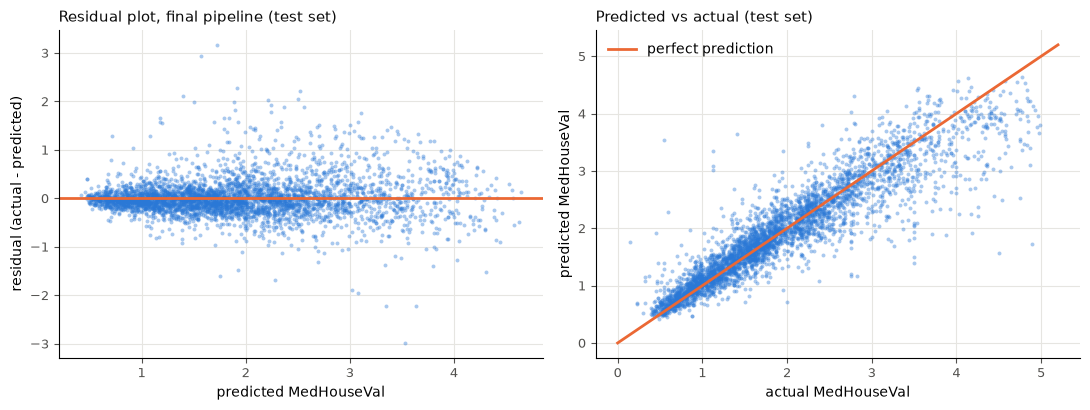

In [13]:
pred_test = best_pipeline.predict(X_test)
resid = y_test - pred_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.scatter(pred_test, resid, s=8, color=BLUE, alpha=0.4, linewidth=0)
ax1.axhline(0, color=ORANGE, linewidth=2)
ax1.set_xlabel("predicted MedHouseVal"); ax1.set_ylabel("residual (actual - predicted)")
ax1.set_title("Residual plot, final pipeline (test set)", loc="left", fontsize=11, color=INK); style(ax1)

ax2.scatter(y_test, pred_test, s=8, color=BLUE, alpha=0.4, linewidth=0)
lims = [0, 5.2]
ax2.plot(lims, lims, color=ORANGE, linewidth=2, label="perfect prediction")
ax2.set_xlabel("actual MedHouseVal"); ax2.set_ylabel("predicted MedHouseVal")
ax2.set_title("Predicted vs actual (test set)", loc="left", fontsize=11, color=INK)
ax2.legend(frameon=False); style(ax2)
fig.tight_layout()
plt.show()

In [14]:
band = pd.cut(y_test, bins=[0, 1.5, 3, 5.0], labels=["cheap (< $150k)", "middle ($150k-$300k)", "expensive (> $300k)"])
pd.DataFrame({"rows": y_test.groupby(band, observed=True).size(),
              "MAE": resid.abs().groupby(band, observed=True).mean(),
              "mean residual (actual - predicted)": resid.groupby(band, observed=True).mean()}).round(3)

,rows,MAE,mean residual (actual - predicted)
MedHouseVal,,,
cheap (< $150k),1510,0.172,-0.102
middle ($150k-$300k),1789,0.231,-0.014
expensive (> $300k),588,0.517,0.381


**អានលទ្ធផល:**
- Pipeline ចុងក្រោយ (test): **MAE 0.2513, RMSE 0.3874, R² 0.8433**។ ល្អជាង XGBoost ក្នុង Lesson 7 (0.2645 / 0.3992 / 0.8336): MAE ទាបជាង **5.0%**, RMSE ទាបជាង **3.0%**។
- **Test RMSE (0.3874) ស្ទើរតែដូចគ្នានឹង CV RMSE (0.3872)**: Cross-Validation ព្យាករលទ្ធផលប្រឡងបានត្រឹមត្រូវ (ការជ្រើស winner ពី 8 បន្សំ ជាភាពសុទិដ្ឋិនិយមតិចតួច ប៉ុន្តែមិនមើលឃើញត្រង់នេះ)។
- **Predicted vs actual:** ពពកចំណុចតឹងជាង Lessons មុនៗ។ សម្រាប់សង្កាត់ថ្លៃបំផុត (actual > 4) ចំណុចនៅតែភាគច្រើនក្រោមបន្ទាត់។ Residual plot នៅតែមានរាងចីវលោ។
- **កំហុសតាមកម្រិតតម្លៃ:**

| កម្រិត | rows | MAE | មធ្យម residual |
|---|---|---|---|
| ថោក (< $150k) | 1,510 | 0.172 ($17,200) | −0.102 (ទាយខ្ពស់ពេក ≈ $10,200) |
| មធ្យម ($150k–$300k) | 1,789 | 0.231 ($23,100) | −0.014 (ស្ទើរតែគ្មានលម្អៀង) |
| ថ្លៃ (> $300k) | 588 | **0.517 ($51,700)** | **+0.381 (ទាយទាបពេក ≈ $38,100)** |

  **Model ខ្សោយបំផុតសម្រាប់សង្កាត់ថ្លៃ**: កំហុសធំជាងសង្កាត់ថោក **3 ដង** ហើយមានលម្អៀងទាប (ទាយទាបជាងតម្លៃពិតជាមធ្យម $38,000)។ ហេតុផលមួយ: យើងបានដក rows ដែលជាប់ cap ($500,001) ដូច្នេះ
  model មិនមានឧទាហរណ៍ "ថ្លៃខ្លាំង" ទេ ហើយតម្លៃពិតរបស់សង្កាត់ថ្លៃរាយប៉ាយច្រើន។ សូមប្រយ័ត្នពេលប្រើ model សម្រាប់សង្កាត់ថ្លៃ។

## 7. Save the fitted pipeline and reload it
`joblib.dump` save object ទាំងមូល: feature engineering, mean/std របស់ scaler និង trees របស់ model។ Folder `models/` ត្រូវបានបន្ថែមក្នុង `.gitignore` (model files ជា binary, អាចធំ, ហើយអាចបង្កើតឡើងវិញពី code)។

In [15]:
MODEL_PATH = Path("../models/house_price_pipeline.joblib")
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(best_pipeline, MODEL_PATH)
{"saved to": str(MODEL_PATH), "size_mb": round(MODEL_PATH.stat().st_size / 1024 ** 2, 2)}

{'saved to': '..\\models\\house_price_pipeline.joblib', 'size_mb': 4.07}

**Reload ក្នុង cell ថ្មី** ហើយទាយសង្កាត់សម្មតិ 2 ដដែលពី Lessons 2–7 ពី **input ដើម**។ យើងប្រើតែ `loaded` (មិនប្រើ `best_pipeline`, `search` ឬ scaler ណាមួយ) ដើម្បីបញ្ជាក់ថា file ដែល save ធ្វើបានគ្រប់យ៉ាង។

In [16]:
loaded = joblib.load("../models/house_price_pipeline.joblib")

new_neighbourhoods = pd.DataFrame([
    {"MedInc": 8.0, "HouseAge": 25, "AveRooms": 6.5, "AveBedrms": 1.0, "Population": 1500,
     "AveOccup": 2.8, "Latitude": 34.05, "Longitude": -118.40},
    {"MedInc": 2.2, "HouseAge": 35, "AveRooms": 4.8, "AveBedrms": 1.1, "Population": 1800,
     "AveOccup": 3.4, "Latitude": 36.75, "Longitude": -119.80},
], index=["high income, Los Angeles coast", "low income, inland Central Valley"])

assert np.allclose(loaded.predict(X_test), pred_test), "reloaded pipeline must give identical predictions"
pd.DataFrame({"price (Pipeline)": loaded.predict(new_neighbourhoods).round(2),
              "price (Lesson 7 model)": lesson7.predict(new_neighbourhoods).round(2)}, index=new_neighbourhoods.index)

,price (Pipeline),price (Lesson 7 model)
"high income, Los Angeles coast",4.55,4.37
"low income, inland Central Valley",0.55,0.57


Pipeline ដែល reload ផ្តល់ការទាយ **ដូចគ្នាទាំងស្រុង** លើ test set (`assert` ជាប់) ហើយទាយសង្កាត់ថ្មីពី raw input ដោយ call តែមួយ។ File ទំហំ ≈ 4 MB។
Pipeline ទាយ Los Angeles = **4.55** ($455,000) និង Central Valley = **0.55** ($55,000)។ ការទាយរបស់ Lesson 7 (កំណែ refit ដោយប្រើ hyperparameters ដែលបានបង្គត់) ខុសគ្នាបន្តិចសម្រាប់ LA (4.37) ព្រោះសង្កាត់ម្នាក់ៗមាន variance ខ្ពស់ជាង score សរុប
(MAE សរុបស្ទើរតែដូចគ្នា ប៉ុន្តែការទាយសង្កាត់តែមួយអាចប្រែប្រួល 0.2 ($20,000) រវាង models ដែលស្រដៀងគ្នា)។

## 8. `src/predict.py`: a command-line prediction script
Script តូចមួយដែល load model ហើយទាយសម្រាប់ CSV ដែលផ្តល់តាម command line។ នេះជារបៀបដែល model ត្រូវបានប្រើក្រៅ notebook។
វាហៅ `apply_cleaning_rules` (ពី `features.py`) ដែលពិនិត្យ columns ហើយរក្សាលំដាប់ដូចពេល train, និង `outside_training_range` ដែលព្រមានពី rows ដែល model មិនដែលឃើញ (`AveRooms > 15` ឬ `AveOccup > 6`)។ អ្វីផ្សេងទៀតធ្វើដោយ pipeline។

In [17]:
print(Path("../src/predict.py").read_text(encoding="utf-8"))

"""Predict the median house value of California neighbourhoods (block groups) from a CSV file.

Usage (from the project root):
    python src/predict.py data/examples/new_neighbourhoods.csv
    python src/predict.py data/examples/new_neighbourhoods.csv --model models/house_price_pipeline.joblib

The CSV needs the columns: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude.
The saved Pipeline engineers features and scales by itself, so pass the raw values.
"""
import argparse
from pathlib import Path

import joblib
import pandas as pd

from features import apply_cleaning_rules, outside_training_range  # also makes HousingFeatures importable for joblib

DEFAULT_MODEL = Path(__file__).resolve().parent.parent / "models" / "house_price_pipeline.joblib"


def main() -> None:
    parser = argparse.ArgumentParser(description="Predict median house value from a CSV of neighbourhoods.")
    parser.add_argument("csv_path", help="CSV file with one neighbourhood (block 

បង្កើត CSV ឧទាហរណ៍ 3 rows ដែលមាន **ករណីពិបាក** ដោយចេតនា:
1. សង្កាត់ Los Angeles ចំណូលខ្ពស់ (ធម្មតា)
2. សង្កាត់ Central Valley ចំណូលទាប (ធម្មតា)
3. សង្កាត់ដែលមាន `AveRooms = 30` (ដូចរមណីយដ្ឋានវិស្សមកាល) = **ក្រៅជួរ training** ដែល model ត្រូវព្រមាន

In [18]:
example_path = Path("../data/examples/new_neighbourhoods.csv")
example_path.parent.mkdir(exist_ok=True)
pd.DataFrame([
    {"MedInc": 8.0, "HouseAge": 25, "AveRooms": 6.5, "AveBedrms": 1.0, "Population": 1500, "AveOccup": 2.8,
     "Latitude": 34.05, "Longitude": -118.40},
    {"MedInc": 2.2, "HouseAge": 35, "AveRooms": 4.8, "AveBedrms": 1.1, "Population": 1800, "AveOccup": 3.4,
     "Latitude": 36.75, "Longitude": -119.80},
    {"MedInc": 4.0, "HouseAge": 30, "AveRooms": 30.0, "AveBedrms": 7.0, "Population": 50, "AveOccup": 2.0,
     "Latitude": 38.90, "Longitude": -120.00},
]).to_csv(example_path, index=False)
print(example_path.read_text())

MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
8.0,25,6.5,1.0,1500,2.8,34.05,-118.4
2.2,35,4.8,1.1,1800,3.4,36.75,-119.8
4.0,30,30.0,7.0,50,2.0,38.9,-120.0



Run script ដូចពី terminal (`python src/predict.py data/examples/new_neighbourhoods.csv`)។ យើងប្រើ `sys.executable` ដើម្បីប្រាកដថាវាប្រើ Python របស់ `.venv`។

In [19]:
run = subprocess.run([sys.executable, "../src/predict.py", str(example_path)], capture_output=True, text=True)
print(run.stdout if run.returncode == 0 else run.stderr)

 MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  predicted_value_usd                warning
    8.0        25       6.5        1.0        1500       2.8     34.05     -118.4               455400                       
    2.2        35       4.8        1.1        1800       3.4     36.75     -119.8                54900                       
    4.0        30      30.0        7.0          50       2.0     38.90     -120.0               144500 outside training range



**អានលទ្ធផល:** Script ដំណើរការពី command line ហើយដោះស្រាយករណីទាំង 3 ដោយគ្មាន error:
- **Row 1** (Los Angeles ចំណូលខ្ពស់): **$455,400**។ ដូចគ្នានឹងការទាយក្នុង Step 7 (4.55)។
- **Row 2** (Central Valley ចំណូលទាប): **$54,900** (0.55)។
- **Row 3** (`AveRooms = 30`): script ព្រមាន **`outside training range`**។ Model នៅតែបញ្ចេញលេខ ($144,500) ប៉ុន្តែយើងមិនគួរទុកចិត្តវាទេ ព្រោះមិនមាន training row ណាដូចនេះ (យើងបានដក `AveRooms > 15` ក្នុង Lesson 1)។

File តែមួយ (`house_price_pipeline.joblib`) + script ≈ 30 បន្ទាត់ = model ដែលប្រើបានក្រៅ notebook។ ដែនកំណត់ដែលត្រូវកត់ត្រា: តម្លៃ < $500,000 ហើយសង្កាត់ធម្មតា ហើយតំបន់ដែលមាន data (Lesson 8)។

## 9. Common Pipeline mistakes checklist
| # | Mistake | Consequence | Fix |
|---|---|---|---|
| 1 | `fit` scaler លើ data ទាំងអស់ មុន split | information ពី test លេចចូល train (leakage) | scaler នៅក្នុង `Pipeline`; `fit` លើ train តែប៉ុណ្ណោះ |
| 2 | Scale ខាងក្រៅ CV | validation fold ប៉ះ scaler (leak តូច ប៉ុន្តែគ្មានមូលហេតុ) | ដាក់ក្នុង `Pipeline` ដើម្បី fit ឡើងវិញក្នុងរាល់ fold |
| 3 | Feature engineering ប្រើស្ថិតិពី data ទាំងអស់ (ឧ. mean) | leakage | ប្រើ transformer ដែល `fit` ក្នុង pipeline ឬ stateless (ដូច `HousingFeatures`) |
| 4 | Save តែ model គ្មាន preprocessing | ពេល load អ្នកគ្មាន scaler/features → ទាយខុស | `joblib.dump(pipeline)` ទាំងមូល |
| 5 | ប្រើ `lambda` ឬ function ក្នុង notebook ក្នុង pipeline | `joblib` មិនអាច load វាពី script ផ្សេង | ដាក់ custom code ក្នុង module (`src/features.py`) |
| 6 | បញ្ជូន columns តាមលំដាប់ខុសទៅ pipeline | ទាយខុសដោយស្ងាត់ស្ងៀម | `apply_cleaning_rules` ជ្រើស columns តាមឈ្មោះ ក្នុងលំដាប់ត្រឹមត្រូវ |
| 7 | ប្រើ model លើ data ក្រៅជួរ training | ទាយដែលមិនអាចទុកចិត្ត | `outside_training_range` ព្រមាន; កត់ត្រាដែនកំណត់ (< $500k, ផ្ទះធម្មតា) |
| 8 | ជឿថា feature engineering ជួយ ដោយមិនវាស់ | ស្មុគស្មាញដោយគ្មានប្រយោជន៍ | ប្រៀបធៀបដោយ CV (Step 5) |

## Lesson summary
- **`Pipeline`** ភ្ជាប់ feature engineering → scaling → model ជា **វត្ថុតែមួយ**: `fit`, `predict`, `GridSearchCV`, `joblib.dump` ទាំងអស់ធ្វើលើវត្ថុនោះ ហើយ preprocessing ត្រូវបាន fit ឡើងវិញក្នុងរាល់ CV fold (គ្មាន leakage)។
- **Custom transformer** (`HousingFeatures` ក្នុង `src/features.py`) ត្រូវតែស្ថិតក្នុង module (មិនមែន lambda ក្នុង notebook) ដើម្បីឲ្យ `joblib` និង script ផ្សេងអាច load។ វា **stateless** (កូអរដោណេទីក្រុងជាថេរ) ដូច្នេះគ្មាន leakage។
- **`GridSearchCV` tune preprocessing និង model ជាមួយគ្នា**: ឈ្មោះ `step__param`, ដាក់ `"passthrough"` ដើម្បីបិទ step។ Pipeline ល្អបំផុត: `HousingFeatures` + `max_depth=7`, CV RMSE 0.3872 ± 0.0083។
- **វាស់ feature engineering:** CV RMSE ធ្លាក់ 3.8% សម្រាប់ XGBoost (0.4024 → 0.3872) និង 5.3% សម្រាប់ Linear Regression (0.5874 → 0.5562)។ ប៉ុន្តែ **`GroupKFold` តាមតំបន់មិនបង្ហាញអត្ថប្រយោជន៍** (0.5644 → 0.5682): features ជួយក្នុងតំបន់ដែល model ស្គាល់ មិនមែនតំបន់ថ្មីទេ។
- **លទ្ធផលចុងក្រោយ (test, បើកម្តង): MAE 0.2513, RMSE 0.3874, R² 0.8433**: ល្អជាង Lesson 7 (0.2645 / 0.3992 / 0.8336)។ Test RMSE ស្ទើរតែដូច CV RMSE (0.3872)។
- **Model ខ្សោយបំផុតសម្រាប់សង្កាត់ថ្លៃ** (> $300k): MAE 0.517 ធំជាងសង្កាត់ថោក 3 ដង ហើយទាយទាបជាង ≈ $38,000។
- **`joblib.dump(pipeline)`** save អ្វីៗទាំងអស់; file ដែល reload ទាយពី raw input ដោយ call តែមួយ។
- **`src/predict.py`** ប្រើ model ពី command line ហើយព្រមានពី rows ក្រៅជួរ training (`AveRooms > 15` ឬ `AveOccup > 6`)។
- ដែនកំណត់: តម្លៃ < $500,000 ហើយសង្កាត់ធម្មតា, ទិន្នន័យឆ្នាំ 1990, តំបន់ដែល model ធ្លាប់ឃើញ (GroupKFold), ទាយទាបជាងសម្រាប់សង្កាត់ថ្លៃ។